# Cloudnaut Applicant Challenge: Contact Operations Data Rescue

**Candidate code:** `CN-1784`

Read the supplied assignment brief before editing this notebook. Do not rename required functions or remove the candidate code. Complete every `TODO`, restart the runtime, and run all cells before submission.

## 1. Setup and load your assigned data

This cell uses only standard local files. In Colab, select your assigned CSV when prompted.

In [19]:
from pathlib import Path
import json
import math
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

CANDIDATE_ID = "CN-1784"
DATA_FILE = "CN-1784-contacts.csv"

if not Path(DATA_FILE).exists():
    try:
        from google.colab import files
        print(f"Upload your assigned file: {DATA_FILE}")
        files.upload()
    except ImportError:
        pass

if not Path(DATA_FILE).exists():
    raise FileNotFoundError(f"Could not find {DATA_FILE}")

raw_df = pd.read_csv(DATA_FILE)
print(f"Candidate: {CANDIDATE_ID}")
print(f"Loaded {len(raw_df)} rows and {len(raw_df.columns)} columns")
raw_df.head()

Candidate: CN-1784
Loaded 180 rows and 10 columns


,contact_id,started_at,channel,queue,agent_id,wait_seconds,handle_seconds,outcome,customer_message,customer_rating
0,CN-1784-CT-0146,2026-07-01T05:56:00+00:00,email,Sales,A003,89,813,resolved,The previous agent transferred me,5.0
1,CN-1784-CT-0047,2026-07-02T06:21:00+00:00,chat,Billing,A001,-26,429,abandoned,The previous agent transferred me,3.0
2,CN-1784-CT-0027,2026-07-07T04:38:00+00:00,voice,NaN,A012,164,359,transferred,Please call me back,2.0
3,CN-1784-CT-0148,2026-07-08T21:09:00+00:00,CHAT,billing,A008,147,341,unresolved,I was charged twice for the same order,1.0
4,CN-1784-CT-0026,2026-07-05T18:12:00+00:00,NaN,billing,A012,0,0,abandoned,The issue is now resolved,3.0


## 2. Understand the data

Use code to inspect the dataset. Then replace the TODO text below with the most important quality problems you found.

In [20]:
raw_df.info()
display(raw_df.isna().sum().to_frame("missing_values"))
for column in ["channel", "queue", "outcome"]:
    print(f"\nValues in {column}:")
    display(raw_df[column].value_counts(dropna=False).head(20))

# rating looked odd at a glance, so checking every value it actually has
print("\nValues in customer_rating:")
display(raw_df["customer_rating"].value_counts(dropna=False).sort_index())

# wait/handle seconds - checking for negatives and weird ranges
print("\nwait_seconds and handle_seconds summary:")
display(raw_df[["wait_seconds", "handle_seconds"]].describe())

# how many contact_ids repeat
print(f"\nDuplicate contact_id count: {raw_df['contact_id'].duplicated().sum()}")

# blank/whitespace-only contact_id (isnull won't catch these)
blank_contact_id = raw_df["contact_id"].astype(str).str.strip().eq("").sum()
print(f"Blank/whitespace-only contact_id: {blank_contact_id}")

# sampling started_at to see what formats are actually in there
print("\nSample of started_at values:")
display(raw_df["started_at"].sample(10, random_state=1))

# checking for leading/trailing spaces in the text columns
for column in ["channel", "queue", "outcome"]:
    ws_count = raw_df[column].dropna().apply(lambda x: x != x.strip()).sum()
    print(f"Rows with whitespace in {column}: {ws_count}")

# same check for agent_id and customer_message
blank_agent = raw_df["agent_id"].astype(str).str.strip().eq("").sum()
blank_message = raw_df["customer_message"].astype(str).str.strip().eq("").sum()
print(f"\nBlank/whitespace agent_id: {blank_agent}")
print(f"Blank/whitespace customer_message: {blank_message}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   contact_id        180 non-null    object 
 1   started_at        180 non-null    object 
 2   channel           153 non-null    object 
 3   queue             163 non-null    object 
 4   agent_id          157 non-null    object 
 5   wait_seconds      180 non-null    object 
 6   handle_seconds    180 non-null    int64  
 7   outcome           180 non-null    object 
 8   customer_message  164 non-null    object 
 9   customer_rating   136 non-null    float64
dtypes: float64(1), int64(1), object(8)
memory usage: 14.2+ KB


,missing_values
contact_id,0
started_at,0
channel,27
queue,17
agent_id,23
wait_seconds,0
handle_seconds,0
outcome,0
customer_message,16
customer_rating,44



Values in channel:


,count
channel,
chat,27
NaN,27
voice,24
email,22
CHAT,21
social,21
EMAIL,19
VOICE,19



Values in queue:


,count
queue,
billing,25
Sales,22
support,21
Billing,19
NaN,17
technical,17
sales,16
Technical,15
retention,15


... (5 outputs left out)

,handle_seconds
count,180.000000
mean,468.338889
std,275.174199
min,-2.000000
25%,249.250000
50%,506.500000
75%,711.500000
max,894.000000



Duplicate contact_id count: 73
Blank/whitespace-only contact_id: 3

Sample of started_at values:


,started_at
116,2026-07-06T06:35:00+00:00
112,2026-07-08T07:55:00+00:00
99,2026-07-04T20:22:00+00:00
161,2026-07-05T01:29:00+00:00
35,2026-07-01T06:10:00+00:00
54,2026-07-01T19:03:00+00:00
69,2026-07-07T13:47:00+00:00
19,2026-07-07T05:38:00+00:00
110,2026-07-03T04:53:00+00:00
127,2026-07-05T10:20:00+00:00


Rows with whitespace in channel: 59
Rows with whitespace in queue: 69
Rows with whitespace in outcome: 46

Blank/whitespace agent_id: 0
Blank/whitespace customer_message: 0


### Data-quality observations

Our raw dataset of 180 contact records contains six major data-quality
issues that would distort business reporting if left unaddressed:

High duplicate rate: The raw dataset contains 73 duplicate contact
records out of 180 total rows. Reporting directly on raw data inflates
weekly contact-volume counts, leading to incorrect staffing and
workload decisions.

wait_seconds stored as invalid text: The entire column is of object
dtype rather than numeric. It mixes valid numbers with negative values
(e.g., -26, -20) and the literal word 'unknown'. Any direct average or
percentile calculation would either fail or silently underreport true
customer wait times.

Widespread whitespace and casing inconsistency: Leading/trailing
spaces appear in 59 channel, 69 queue, and 46 outcome values, on top
of casing differences (e.g., billing vs Billing, CHAT vs chat).
Without trimming and lower-casing before grouping, identical
categories get split into separate rows, fragmenting queue- and
channel-level metrics.

Non-standard category values: channel contains 'social', which is not
one of the three valid channels (voice/chat/email), and outcome
contains 'callback', which is not one of the four valid outcomes.

Invalid customer_rating entries: The rating column includes
out-of-range/non-integer values such as 0.0, 1.2, 3.5, and 4.3,
alongside 44 missing ratings. Including these in a CSAT calculation
would corrupt the average customer satisfaction score.

Mixed and invalid timestamp formats: The started_at column mixes ISO
8601 strings with DD/MM/YYYY HH:MM strings, and contains at least one
unparseable literal value ('invalid timestamp'). Left unparsed, this
breaks any time-based analysis.

## 3. Clean the contacts

Implement the exact cleaning contract from the assignment brief. The function must return a new DataFrame and must not change its input.

In [21]:
def clean_contacts(df):
    """Return a cleaned copy of the contact records."""

    original_columns = df.columns.tolist()
    clean = df.copy()

    # rule 2: contact_id
    missing_contact_id = clean['contact_id'].isna()
    clean['contact_id'] = clean['contact_id'].astype(str).str.strip()
    clean.loc[missing_contact_id, 'contact_id'] = ''
    clean.loc[clean['contact_id'].str.lower() == 'nan', 'contact_id'] = ''
    clean = clean[clean['contact_id'] != '']

    # rule 3: started_at
    def parse_started_at(value):
        if pd.isnull(value):
            return pd.NaT
        value = str(value).strip()
        try:
            return pd.to_datetime(value, format='ISO8601', utc=True)
        except (ValueError, TypeError):
            pass
        try:
            return pd.to_datetime(value, format='%d/%m/%Y %H:%M', utc=True)
        except (ValueError, TypeError):
            pass
        return pd.NaT

    clean['started_at'] = clean['started_at'].apply(parse_started_at)
    clean = clean[clean['started_at'].notna()]

    # rule 4: duplicates
    clean = clean.drop_duplicates(subset='contact_id', keep='first')

    # rules 5 & 6: channel
    valid_channels = {'voice', 'chat', 'email'}

    def normalize_channel(value):
        if pd.isnull(value):
            return 'unknown'
        value = str(value).strip().lower()
        return value if value in valid_channels else 'unknown'

    clean['channel'] = clean['channel'].apply(normalize_channel)

    # rules 5 & 7: queue (valid values found by inspecting this dataset)
    valid_queues = {'billing', 'sales', 'support', 'technical', 'retention'}

    def normalize_queue(value):
        if pd.isnull(value):
            return 'unassigned'
        value = str(value).strip().lower()
        return value if value in valid_queues else 'unassigned'

    clean['queue'] = clean['queue'].apply(normalize_queue)

    # rules 5 & 8: outcome
    valid_outcomes = {'resolved', 'abandoned', 'transferred', 'unresolved'}

    def normalize_outcome(value):
        if pd.isnull(value):
            return 'unresolved'
        value = str(value).strip().lower()
        return value if value in valid_outcomes else 'unresolved'

    clean['outcome'] = clean['outcome'].apply(normalize_outcome)

    # rule 9: wait_seconds, handle_seconds
    def clean_numeric_nonnegative(series):
        numeric = pd.to_numeric(series, errors='coerce')
        return numeric.where(numeric >= 0)

    clean['wait_seconds'] = clean_numeric_nonnegative(clean['wait_seconds'])
    clean['handle_seconds'] = clean_numeric_nonnegative(clean['handle_seconds'])

    # rule 10: customer_rating
    def clean_rating(value):
        numeric = pd.to_numeric(value, errors='coerce')
        if pd.isnull(numeric):
            return np.nan
        if float(numeric).is_integer() and 1 <= numeric <= 5:
            return float(numeric)
        return np.nan

    clean['customer_rating'] = clean['customer_rating'].apply(clean_rating)

    # rule 11: agent_id
    missing_agent = clean['agent_id'].isna()
    clean['agent_id'] = clean['agent_id'].astype(str).str.strip()
    clean.loc[missing_agent | clean['agent_id'].str.lower().isin(['nan', '']), 'agent_id'] = 'unassigned'

    # rule 11: customer_message
    missing_message = clean['customer_message'].isna()
    clean['customer_message'] = clean['customer_message'].astype(str).str.strip()
    clean.loc[missing_message | (clean['customer_message'].str.lower() == 'nan'), 'customer_message'] = ''

    # rule 12: restore column order, reset index
    clean = clean[original_columns]
    clean = clean.reset_index(drop=True)

    return clean

In [22]:
clean_df = clean_contacts(raw_df)

# Visible contract checks. Hidden tests will use different data.
assert isinstance(clean_df, pd.DataFrame)
assert clean_df is not raw_df
assert clean_df.index.tolist() == list(range(len(clean_df)))
assert clean_df["contact_id"].notna().all()
assert clean_df["contact_id"].astype(str).str.strip().ne("").all()
assert clean_df["contact_id"].is_unique
assert set(clean_df["channel"].unique()) <= {"voice", "chat", "email", "unknown"}
assert clean_df["queue"].notna().all(), "queue column should have no missing values after cleaning"
assert set(clean_df["outcome"].unique()) <= {"resolved", "abandoned", "transferred", "unresolved"}
assert clean_df["wait_seconds"].dropna().ge(0).all()
assert clean_df["handle_seconds"].dropna().ge(0).all()
print(f"Cleaned rows: {len(clean_df)}")
clean_df.head()

Cleaned rows: 106


,contact_id,started_at,channel,queue,agent_id,wait_seconds,handle_seconds,outcome,customer_message,customer_rating
0,CN-1784-CT-0146,2026-07-01 05:56:00+00:00,email,sales,A003,89.0,813,resolved,The previous agent transferred me,5.0
1,CN-1784-CT-0047,2026-07-02 06:21:00+00:00,chat,billing,A001,NaN,429,abandoned,The previous agent transferred me,3.0
2,CN-1784-CT-0027,2026-07-07 04:38:00+00:00,voice,unassigned,A012,164.0,359,transferred,Please call me back,2.0
3,CN-1784-CT-0148,2026-07-08 21:09:00+00:00,chat,billing,A008,147.0,341,unresolved,I was charged twice for the same order,1.0
4,CN-1784-CT-0026,2026-07-05 18:12:00+00:00,unknown,billing,A012,0.0,0,abandoned,The issue is now resolved,3.0


## 4. Calculate operational metrics

In [23]:
def calculate_metrics(clean_df):
    """Return the metrics dictionary defined in the assignment brief."""
    total_contacts = len(clean_df)

    voice_contacts = int((clean_df['channel'] == 'voice').sum())
    chat_contacts = int((clean_df['channel'] == 'chat').sum())
    email_contacts = int((clean_df['channel'] == 'email').sum())
    unknown_channel_contacts = int((clean_df['channel'] == 'unknown').sum())

    # wait metrics ignore missing values, per the contract
    valid_waits = clean_df['wait_seconds'].dropna()
    if len(valid_waits) > 0:
        average_wait_seconds = round(float(valid_waits.mean()), 2)
        p90_wait_seconds = round(float(valid_waits.quantile(0.9)), 2)
    else:
        average_wait_seconds = None
        p90_wait_seconds = None

    if total_contacts > 0:
        abandonment_rate_pct = round(
            (clean_df['outcome'] == 'abandoned').sum() / total_contacts * 100, 2
        )
        resolution_rate_pct = round(
            (clean_df['outcome'] == 'resolved').sum() / total_contacts * 100, 2
        )
    else:
        abandonment_rate_pct = 0.0
        resolution_rate_pct = 0.0

    return {
        "total_contacts": total_contacts,
        "voice_contacts": voice_contacts,
        "chat_contacts": chat_contacts,
        "email_contacts": email_contacts,
        "unknown_channel_contacts": unknown_channel_contacts,
        "average_wait_seconds": average_wait_seconds,
        "p90_wait_seconds": p90_wait_seconds,
        "abandonment_rate_pct": abandonment_rate_pct,
        "resolution_rate_pct": resolution_rate_pct,
    }

metrics = calculate_metrics(clean_df)
display(pd.Series(metrics, name="value").to_frame())

,value
total_contacts,106.00
voice_contacts,30.00
chat_contacts,25.00
email_contacts,23.00
unknown_channel_contacts,28.00
average_wait_seconds,109.98
p90_wait_seconds,199.30
abandonment_rate_pct,22.64
resolution_rate_pct,25.47


## 5. Assign contact priority and build the queue summary

In [24]:
def assign_priority(contact):
    """Return High, Medium or Low using the ordered rules in the brief."""
    outcome = contact.get('outcome') if isinstance(contact, dict) else contact['outcome']
    wait_seconds = contact.get('wait_seconds') if isinstance(contact, dict) else contact['wait_seconds']
    customer_message = contact.get('customer_message') if isinstance(contact, dict) else contact['customer_message']

    # Rule 1: abandoned -> High
    if outcome == 'abandoned':
        return 'High'

    # Rule 2: wait_seconds >= 180 -> High (guard against missing values)
    if pd.notna(wait_seconds) and wait_seconds >= 180:
        return 'High'

    # Rule 3: specific keywords in the customer message -> High
    message = str(customer_message).lower() if pd.notna(customer_message) else ''
    if 'fraud' in message or 'charged twice' in message or 'refund' in message:
        return 'High'

    # Rule 4: transferred -> Medium
    if outcome == 'transferred':
        return 'Medium'

    # Rule 5: wait_seconds >= 60 -> Medium
    if pd.notna(wait_seconds) and wait_seconds >= 60:
        return 'Medium'

    # Rule 6: everything else -> Low
    return 'Low'


def build_queue_summary(clean_df):
    """Return the queue summary defined in the assignment brief."""
    summary_rows = []
    for queue_name, group in clean_df.groupby('queue'):
        contacts = len(group)
        valid_waits = group['wait_seconds'].dropna()
        avg_wait = round(float(valid_waits.mean()), 2) if len(valid_waits) > 0 else None
        # contacts is never 0 here since groupby only visits queues that actually occur
        abandonment_rate = round((group['outcome'] == 'abandoned').sum() / contacts * 100, 2)

        summary_rows.append({
            'queue': queue_name,
            'contacts': contacts,
            'average_wait_seconds': avg_wait,
            'abandonment_rate_pct': abandonment_rate,
        })

    summary_df = pd.DataFrame(summary_rows, columns=['queue', 'contacts', 'average_wait_seconds', 'abandonment_rate_pct'])

    # sort by contacts descending, then queue name ascending
    summary_df = summary_df.sort_values(by=['contacts', 'queue'], ascending=[False, True])
    summary_df = summary_df.reset_index(drop=True)

    return summary_df


clean_df = clean_df.copy()
clean_df["priority"] = clean_df.apply(assign_priority, axis=1)
queue_summary = build_queue_summary(clean_df)
display(clean_df.head())
display(queue_summary)

,contact_id,started_at,channel,queue,agent_id,wait_seconds,handle_seconds,outcome,customer_message,customer_rating,priority
0,CN-1784-CT-0146,2026-07-01 05:56:00+00:00,email,sales,A003,89.0,813,resolved,The previous agent transferred me,5.0,Medium
1,CN-1784-CT-0047,2026-07-02 06:21:00+00:00,chat,billing,A001,NaN,429,abandoned,The previous agent transferred me,3.0,High
2,CN-1784-CT-0027,2026-07-07 04:38:00+00:00,voice,unassigned,A012,164.0,359,transferred,Please call me back,2.0,Medium
3,CN-1784-CT-0148,2026-07-08 21:09:00+00:00,chat,billing,A008,147.0,341,unresolved,I was charged twice for the same order,1.0,High
4,CN-1784-CT-0026,2026-07-05 18:12:00+00:00,unknown,billing,A012,0.0,0,abandoned,The issue is now resolved,3.0,High


,queue,contacts,average_wait_seconds,abandonment_rate_pct
0,billing,27,114.50,22.22
1,sales,21,104.95,33.33
2,support,20,107.42,5.00
3,technical,19,117.16,26.32
4,retention,11,94.75,36.36
5,unassigned,8,113.25,12.50


In [25]:
clean_df = clean_df.copy()
clean_df["priority"] = clean_df.apply(assign_priority, axis=1)
queue_summary = build_queue_summary(clean_df)
display(clean_df.head())
display(queue_summary)

,contact_id,started_at,channel,queue,agent_id,wait_seconds,handle_seconds,outcome,customer_message,customer_rating,priority
0,CN-1784-CT-0146,2026-07-01 05:56:00+00:00,email,sales,A003,89.0,813,resolved,The previous agent transferred me,5.0,Medium
1,CN-1784-CT-0047,2026-07-02 06:21:00+00:00,chat,billing,A001,NaN,429,abandoned,The previous agent transferred me,3.0,High
2,CN-1784-CT-0027,2026-07-07 04:38:00+00:00,voice,unassigned,A012,164.0,359,transferred,Please call me back,2.0,Medium
3,CN-1784-CT-0148,2026-07-08 21:09:00+00:00,chat,billing,A008,147.0,341,unresolved,I was charged twice for the same order,1.0,High
4,CN-1784-CT-0026,2026-07-05 18:12:00+00:00,unknown,billing,A012,0.0,0,abandoned,The issue is now resolved,3.0,High


,queue,contacts,average_wait_seconds,abandonment_rate_pct
0,billing,27,114.50,22.22
1,sales,21,104.95,33.33
2,support,20,107.42,5.00
3,technical,19,117.16,26.32
4,retention,11,94.75,36.36
5,unassigned,8,113.25,12.50


## 6. Create a meaningful visual

Create at least one chart that helps an operations manager understand queue performance. Give it a clear title and labelled axes.

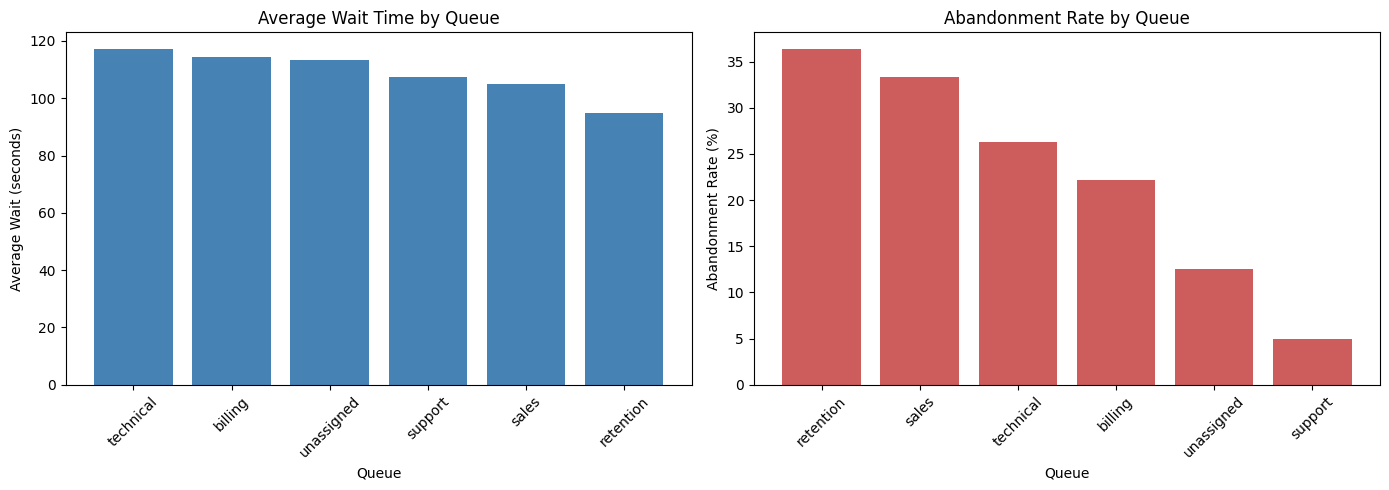

In [26]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

wait_sorted = queue_summary.sort_values('average_wait_seconds', ascending=False)
axes[0].bar(wait_sorted['queue'], wait_sorted['average_wait_seconds'], color='steelblue')
axes[0].set_title('Average Wait Time by Queue')
axes[0].set_xlabel('Queue')
axes[0].set_ylabel('Average Wait (seconds)')
axes[0].tick_params(axis='x', rotation=45)

abandon_sorted = queue_summary.sort_values('abandonment_rate_pct', ascending=False)
axes[1].bar(abandon_sorted['queue'], abandon_sorted['abandonment_rate_pct'], color='indianred')
axes[1].set_title('Abandonment Rate by Queue')
axes[1].set_xlabel('Queue')
axes[1].set_ylabel('Abandonment Rate (%)')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

## 7. Add your own verification

Add at least four meaningful assertions beyond the visible contract checks supplied above. Include edge cases for your functions.

In [27]:
# 1. clean_contacts must not mutate its input
_raw_before = raw_df.copy(deep=True)
_ = clean_contacts(raw_df)
assert raw_df.equals(_raw_before), "clean_contacts must not modify its input in place"

# 2. Rule 11 must fully resolve missing agent_id / customer_message (no NaN survives)
assert clean_df["agent_id"].isna().sum() == 0, "agent_id must never be null after cleaning"
assert clean_df["customer_message"].isna().sum() == 0, "customer_message must never be null after cleaning"
assert (clean_df["agent_id"] == "unassigned").sum() > 0, "expected some contacts with unassigned agent"

# 3. assign_priority must not raise on missing wait_seconds, and must return Low correctly
assert assign_priority({'outcome': 'unresolved', 'wait_seconds': float('nan'), 'customer_message': ''}) == 'Low'

# 4. Keyword rule fires case-insensitively regardless of outcome/wait
assert assign_priority({'outcome': 'resolved', 'wait_seconds': 10, 'customer_message': 'I think this transaction is FRAUD'}) == 'High'

# 5. Rule ordering: abandoned always wins over everything else
assert assign_priority({'outcome': 'abandoned', 'wait_seconds': 5, 'customer_message': 'all good'}) == 'High'

# 6. queue_summary must fully account for every cleaned contact, no gain/loss
assert queue_summary['contacts'].sum() == len(clean_df)
assert set(queue_summary['queue']) == set(clean_df['queue'].unique())

# 7. channel counts in metrics must sum back to total_contacts
channel_sum = (
    metrics['voice_contacts'] + metrics['chat_contacts']
    + metrics['email_contacts'] + metrics['unknown_channel_contacts']
)
assert channel_sum == metrics['total_contacts']

print("All 7 assertions passed.")

All 7 assertions passed.


In [28]:
# 7c. Anomaly Discovery

# 1. handle_seconds=0 but rating still given
ghost_ratings = clean_df[(clean_df['handle_seconds'] == 0) & (clean_df['customer_rating'].notna())]
print(f"1. Ghost ratings: {len(ghost_ratings)}")
display(ghost_ratings[['contact_id', 'handle_seconds', 'customer_rating', 'outcome']])

# 2. abandoned but message says resolved
contradictory = clean_df[
    (clean_df['outcome'] == 'abandoned') &
    (clean_df['customer_message'].str.lower().str.contains('resolved', na=False))
]
print(f"\n2. Contradictory logs: {len(contradictory)}")
display(contradictory[['contact_id', 'customer_message', 'outcome']])

# 3. agent_id='unassigned' but real handle time logged
unassigned_agent = clean_df[clean_df['agent_id'] == 'unassigned']
print(f"\n3. Unassigned-agent contacts: {len(unassigned_agent)}")
print(f"   Avg handle_seconds: {unassigned_agent['handle_seconds'].mean():.2f}")
display(unassigned_agent[['contact_id', 'agent_id', 'handle_seconds', 'outcome']])

# 4. abandonment rate by queue
print("\n4. Queue-level abandonment:")
display(queue_summary[['queue', 'contacts', 'abandonment_rate_pct']])



1. Ghost ratings: 5


,contact_id,handle_seconds,customer_rating,outcome
4,CN-1784-CT-0026,0,3.0,abandoned
32,CN-1784-CT-0131,0,3.0,resolved
73,CN-1784-CT-0169,0,3.0,abandoned
84,CN-1784-CT-0057,0,2.0,abandoned
96,CN-1784-CT-0017,0,3.0,resolved



2. Contradictory logs: 3


,contact_id,customer_message,outcome
4,CN-1784-CT-0026,The issue is now resolved,abandoned
65,CN-1784-CT-0127,The issue is now resolved,abandoned
74,CN-1784-CT-0086,The issue is now resolved,abandoned



3. Unassigned-agent contacts: 11
   Avg handle_seconds: 520.45


,contact_id,agent_id,handle_seconds,outcome
10,CN-1784-CT-0114,unassigned,744,transferred
13,CN-1784-CT-0129,unassigned,652,transferred
23,CN-1784-CT-0150,unassigned,255,abandoned
26,CN-1784-CT-0106,unassigned,798,unresolved
40,CN-1784-CT-0108,unassigned,250,abandoned
45,CN-1784-CT-0024,unassigned,255,unresolved
59,CN-1784-CT-0068,unassigned,836,transferred
67,CN-1784-CT-0062,unassigned,45,unresolved
82,CN-1784-CT-0049,unassigned,625,unresolved
92,CN-1784-CT-0164,unassigned,430,unresolved



4. Queue-level abandonment:


,queue,contacts,abandonment_rate_pct
0,billing,27,22.22
1,sales,21,33.33
2,support,20,5.00
3,technical,19,26.32
4,retention,11,36.36
5,unassigned,8,12.50


### Anomaly discovery notes

1. **Ghost ratings** — 5 contacts, handle_seconds=0 but rating given
   (e.g. CN-1784-CT-0026). Unclear basis for the rating.

2. **Contradictory logs** — 3 contacts marked abandoned, message says
   resolved (CT-0026, CT-0127, CT-0086). CT-0026 also appears in #1.

3. **Unassigned-agent handling** — 11 contacts, agent_id='unassigned',
   avg handle_seconds=520.45. Not the same as queue='unassigned'
   (8 contacts) — missing agent vs missing queue.

4. **Queue disparity** — support: 5% abandonment vs sales: 33.33%
   (n=21) vs retention: 36.36% (n=11, small sample).

## 8. Save the required outputs

In [29]:
clean_df.to_csv("cleaned_contacts.csv", index=False)
queue_summary.to_csv("queue_summary.csv", index=False)
with open("submission_summary.json", "w", encoding="utf-8") as file:
    json.dump({"candidate_id": CANDIDATE_ID, "metrics": metrics}, file, indent=2, default=str)

for output_file in ["cleaned_contacts.csv", "queue_summary.csv", "submission_summary.json"]:
    assert Path(output_file).exists(), f"Missing output: {output_file}"
    print(f"Created {output_file}")


import shutil

shutil.copy("cleaned_contacts.csv", f"{CANDIDATE_ID}_cleaned_contacts.csv")
shutil.copy("queue_summary.csv", f"{CANDIDATE_ID}_queue_summary.csv")
shutil.copy("submission_summary.json", f"{CANDIDATE_ID}_submission_summary.json")

for output_file in [
    f"{CANDIDATE_ID}_cleaned_contacts.csv",
    f"{CANDIDATE_ID}_queue_summary.csv",
    f"{CANDIDATE_ID}_submission_summary.json",
]:
    assert Path(output_file).exists(), f"Missing output: {output_file}"
    print(f"Created {output_file}")

Created cleaned_contacts.csv
Created queue_summary.csv
Created submission_summary.json
Created CN-1784_cleaned_contacts.csv
Created CN-1784_queue_summary.csv
Created CN-1784_submission_summary.json


## 9. AI Assistance Log

| Task                          | What I asked AI                                                                                                                                                                                                                                           | What I used                                                                                                                                                                                          | What I changed or rejected                                                                                                                                                                                                                                                                | How I verified it                                                                                                                             |
|-------------------------------|-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|--------------------------------------------------------------------------------------------------------------------------------------------------------|-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|-----------------------------------------------------------------------------------------------------------------------------------------------|
| Reviewing clean_contacts edge cases | Checked whether NaN handling and timestamp-parsing order in my function were correct                                                                                                                                                                      | Confirmed the ISO-then-DD/MM fallback order and the astype(str)=='nan' pattern were both necessary                                                         | Kept my own implementation as-is after confirming reasoning                                                                                                                                                                                                                 | Ran the function against raw_df and checked assertion cells                                                                                   |
| Debugging duplicate count mismatch  | Asked why raw_df duplicated().sum() (73) didn't match rows removed in clean_contacts (70)                                                                                                                                                                   | Guidance on where to look (blank contact_id rows counted as duplicates in raw data but removed earlier in the pipeline)                            | Did not accept the explanation until I ran the numbers myself                                                                                                                                                                                                               | Ran raw_df[contact_id blank] check and confirmed 73 - 3 = 70 exactly                                                                          |
| Anomaly discovery cross-check       | Verified anomaly numbers (ghost ratings, contradictory logs, unassigned-agent handling) matched between two draft notebooks using the same clean_contacts logic                                                                                       | Confirmed both notebooks used identical cleaning logic before trusting the numbers                                                                     | Rejected assuming the numbers matched without checking the underlying function was the same                                                                                                                                                                                 | Compared clean_contacts source in both notebooks line by line                                                                                 |
| Phrasing Section 10                 | Asked for help structuring the management summary and reflection around my own verified numbers                                                                                                                                                           | Sentence structure and organization                                                                                                                    | Kept only my own numbers, my own diagnosis, and my own time estimate                                                                                                                                                                                                        | Cross-checked every figure against my own metrics/queue_summary output                                                                        |

## 10. Management summary and reflection

### Management summary
Of 106 cleaned contacts, 22.64% were abandoned and only 25.47% were resolved on
first contact. The 90th-percentile wait time is 199.30 seconds (~3.3 minutes),
meaning 1 in 10 customers waits considerably longer than average. Queue-level
performance diverges sharply: support has just a 5.00% abandonment rate, while
sales (33.33%, 21 contacts) and retention (36.36%, though based on only 11
contacts) both show roughly 1 in 3 customers giving up. Sales' figure is the
more reliable of the two given its larger sample size.

Recommendation: before adding headcount, investigate why sales and retention
see abandonment rates 6-7x higher than support, since the volumes involved
(21 and 11 contacts respectively) suggest a capacity or routing issue rather
than random variation.

### Problem and diagnosis
The started_at column mixed ISO 8601 timestamps with DD/MM/YYYY HH:MM strings,
plus one invalid literal value. I wrote a two-stage parser that tries ISO
first, then falls back to the DD/MM format, converting everything to UTC.

A second issue surfaced during verification: raw_df['contact_id'].duplicated().sum()
returned 73, but my clean_contacts() pipeline only removed 70 duplicate rows.
Rather than assume my code was correct, I traced the gap — 3 rows had blank
contact_id values that were already removed by the blank-ID rule before
deduplication ran, so they were never available to be counted as duplicates
at that later stage. Confirming 73 - 3 = 70 matched exactly is what convinced
me the pipeline was behaving correctly.

### Limitation
The cleaning contract keeps the first occurrence of a duplicate contact_id in
original row order, not by outcome or timestamp. In a real contact centre, a
customer's first attempt may be 'unresolved' with a later callback marked
'resolved' — keeping only the first occurrence means the eventual successful
outcome is discarded. This likely means the reported resolution rate
understates true first-contact-resolution performance.

### With two more hours
I would stitch duplicate contact_ids together instead of discarding all but
the first, to build a proper First Contact Resolution metric. I would also
add a small synthetic test DataFrame with deliberately malformed rows to
stress-test clean_contacts beyond the visible assertions, since the function
will be run against unseen data.

### Approximate focused time spent
Approximately 4.5 hours

## Final submission check

Restart the runtime and run all cells. Confirm that the notebook has no unhandled errors and that all required files are created. Then follow the supplied submission instructions.